# Hito 4 — Clustering exploratorio de características acústicas

**Proyecto 1 de Innovación Tecnológica · Maestría en Inteligencia Artificial Aplicada · Universidad Icesi**

Este notebook reproduce explícitamente el flujo de `src/training/hito4_clustering.py`: preparación de datos, estandarización, K-Means, evaluación y visualización. Se excluye `test`; las etiquetas de especie solo se usan para evaluar después del clustering, nunca para ajustarlo.

**Objetivo:** comprobar si K-Means (k = 16) agrupa clips de 5 s de forma consistente con las 16 especies y evaluar la sensibilidad a la semilla aleatoria.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FEATURES_CSV = PROJECT_ROOT / "src" / "data" / "features" / "features.csv"
HITO3_SUMMARY = PROJECT_ROOT / "experiments" / "results" / "hito3" / "hito3_summary.json"
OUT_DIR = PROJECT_ROOT / "experiments" / "results" / "hito4_5" / "clustering"
SEED = 42
N_CLUSTERS = 16
SEED_VALIDATION = [42, 7, 21, 99, 123]
SEED_SILHOUETTE_SAMPLE_SIZE = 17893

print(f"Directorio del proyecto: {PROJECT_ROOT}")
print(f"Archivo de características encontrado: {FEATURES_CSV.is_file()}")

Directorio del proyecto: /Users/veroserna1/Github repositories/Proyecto 1 MIAA
Archivo de características encontrado: True


## Paso 1 — Cargar y delimitar los datos

Se usan las columnas de características declaradas por el Hito 3. Se filtra `partition == "test"` para no incluir el conjunto reservado. La etiqueta `primary_label` se conserva aparte para la evaluación posterior.

In [2]:
with HITO3_SUMMARY.open(encoding="utf-8") as file:
    feature_columns = json.load(file)["feature_columns"]

df = pd.read_csv(FEATURES_CSV)
df = df.loc[df["partition"] != "test"].reset_index(drop=True)

X = df[feature_columns].to_numpy(dtype=np.float64)
y_species = df["primary_label"].to_numpy()
train_mask = df["partition"].eq("train").to_numpy()

print(f"Clips train + val: {len(df):,}")
print(f"Número de características: {len(feature_columns)}")
print(f"Clips train para ajustar el escalador: {train_mask.sum():,}")
print(f"Número de especies: {df['primary_label'].nunique()}")

Clips train + val: 17,893
Número de características: 90
Clips train para ajustar el escalador: 14,296
Número de especies: 16


## Paso 2 — Estandarizar las características

El escalador se ajusta únicamente con `train` y luego transforma `train + val`. Así, validación no participa en el cálculo de medias ni desviaciones. K-Means usa distancia euclidiana, por lo que la escala de las variables importa.

In [3]:
scaler = StandardScaler().fit(X[train_mask])
X_scaled = scaler.transform(X)

print(f"Matriz estandarizada: {X_scaled.shape}")
print(f"Medias de train (primeras 5 características): {scaler.mean_[:5]}")

Matriz estandarizada: (17893, 90)
Medias de train (primeras 5 características): [-1.05797240e-07 -3.98056078e-09 -1.66677305e-08 -1.17054082e-08
  7.48755714e-09]


## Paso 3 — Ajustar K-Means y evaluar la corrida principal

K-Means se ajusta sin etiquetas de especie. Se fija `random_state=42` y `n_init=10`. ARI compara los clusters con las especies reales; Silhouette mide cohesión y separación usando solo los clusters. La métrica Silhouette principal se calcula sobre todos los clips.

In [4]:
kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=SEED, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)

ari = adjusted_rand_score(y_species, cluster_labels)
silhouette_full = silhouette_score(
    X_scaled, cluster_labels, sample_size=len(X_scaled), random_state=SEED
)

print(f"Semilla: {SEED} | k: {N_CLUSTERS} | n_init: 10")
print(f"ARI (clusters vs. especies): {ari:.4f}")
print(f"Silhouette (todos los {len(X_scaled):,} clips): {silhouette_full:.4f}")

Semilla: 42 | k: 16 | n_init: 10
ARI (clusters vs. especies): 0.0320
Silhouette (todos los 17,893 clips): 0.0206


## Paso 4 — Validar estabilidad con distintas semillas

Se repite el ajuste con cinco semillas, manteniendo fijos los datos, el escalado, k y `n_init`. Se informa ARI contra las especies y Silhouette sobre **los 17.893 clips completos** en cada semilla; por lo tanto, la comparación usa los mismos datos, no una submuestra. También se calcula ARI entre cada par de particiones: este indicador no depende de los números arbitrarios asignados a los clusters.

La Silhouette de esta tabla se calcula sobre todos los clips en cada ejecución y es comparable con la métrica principal.

In [5]:
seed_labels = {}
seed_results = []

for seed in SEED_VALIDATION:
    labels = cluster_labels if seed == SEED else KMeans(
        n_clusters=N_CLUSTERS, random_state=seed, n_init=10
    ).fit_predict(X_scaled)
    seed_labels[seed] = labels
    seed_results.append(
        {
            "semilla": seed,
            "ARI_vs_especie": adjusted_rand_score(y_species, labels),
            "Silhouette_todos_los_clips": silhouette_score(
                X_scaled,
                labels,
                sample_size=min(SEED_SILHOUETTE_SAMPLE_SIZE, len(X_scaled)),
                random_state=2026,
            ),
        }
    )

seed_metrics = pd.DataFrame(seed_results).set_index("semilla")
seed_comparison = pd.DataFrame(
    {
        seed_a: {
            seed_b: adjusted_rand_score(seed_labels[seed_a], seed_labels[seed_b])
            for seed_b in SEED_VALIDATION
        }
        for seed_a in SEED_VALIDATION
    }
)

print("Métricas por semilla:")
display(seed_metrics.round(4))
print("ARI entre particiones (1.0 = particiones idénticas, salvo permutación de etiquetas):")
display(seed_comparison.round(4))
print(
    "Rango de ARI vs. especie: "
    f"{seed_metrics['ARI_vs_especie'].min():.4f}–{seed_metrics['ARI_vs_especie'].max():.4f}"
)
print(
    "Rango de Silhouette sobre todos los clips: "
    f"{seed_metrics['Silhouette_todos_los_clips'].min():.4f}–"
    f"{seed_metrics['Silhouette_todos_los_clips'].max():.4f}"
)

Métricas por semilla:


,ARI_vs_especie,Silhouette_todos_los_clips
semilla,,
42,0.0320,0.0206
7,0.0312,0.0201
21,0.0322,0.0173
99,0.0308,0.0186
123,0.0335,0.0163


ARI entre particiones (1.0 = particiones idénticas, salvo permutación de etiquetas):


,42,7,21,99,123
42,1.0000,0.8913,0.6346,0.8510,0.6400
7,0.8913,1.0000,0.5951,0.8165,0.6045
21,0.6346,0.5951,1.0000,0.5950,0.8812
99,0.8510,0.8165,0.5950,1.0000,0.5897
123,0.6400,0.6045,0.8812,0.5897,1.0000


Rango de ARI vs. especie: 0.0308–0.0335
Rango de Silhouette sobre todos los clips: 0.0163–0.0206


## Paso 5 — Visualizar PCA y relación con el ruido

PCA se ajusta con el conjunto `train` estandarizado y se proyectan todos los clips train + val. Las figuras son una proyección 2D (coloreada por cluster y especie), la proyección 3D y la relación de SNR con la alineación/distancia al centroide. Las proyecciones facilitan la inspección visual, pero no sustituyen las métricas calculadas en las 90 dimensiones.

Varianza explicada por PC1, PC2 y PC3: [0.2594 0.0594 0.0478]


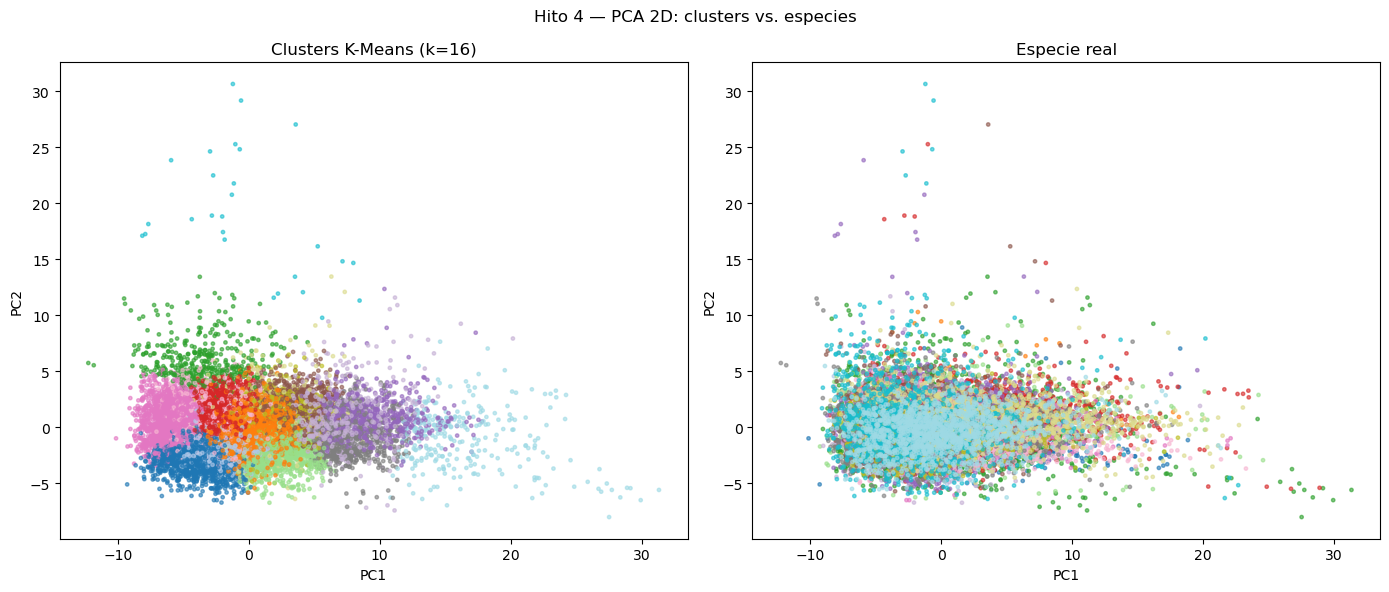

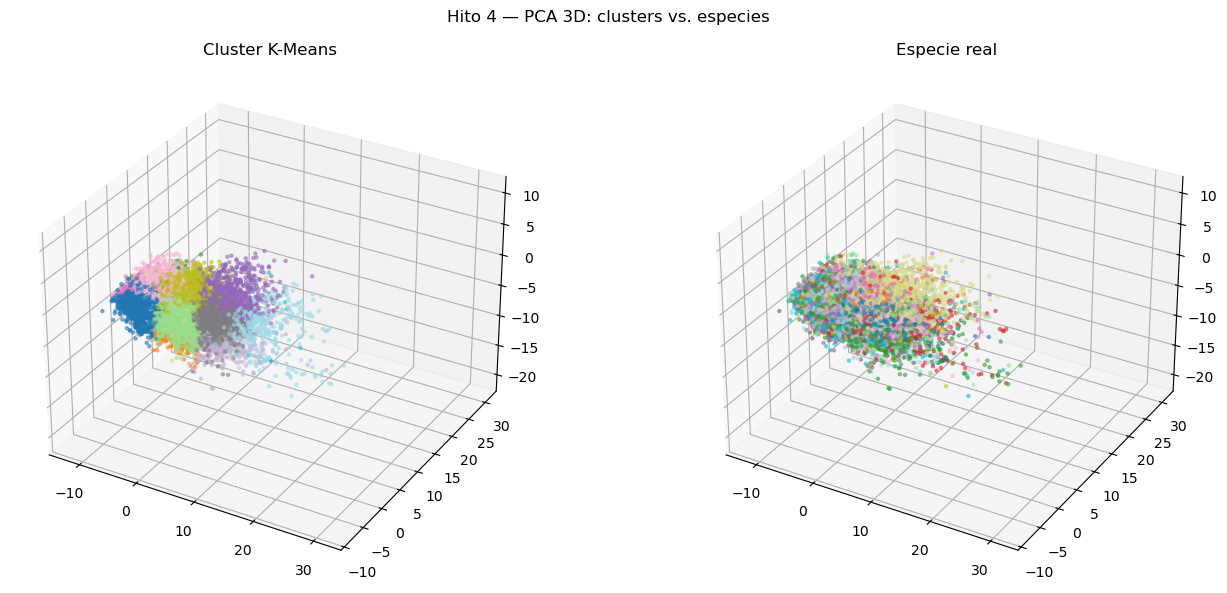

In [6]:
from io import BytesIO
from IPython.display import Image

def display_figure(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

pca = PCA(n_components=3, random_state=SEED).fit(X_scaled[train_mask])
coords = pca.transform(X_scaled)
species_codes, species_idx = np.unique(y_species, return_inverse=True)
print("Varianza explicada por PC1, PC2 y PC3:", pca.explained_variance_ratio_.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].scatter(coords[:, 0], coords[:, 1], c=cluster_labels, cmap="tab20", s=6, alpha=0.6)
axes[0].set_title(f"Clusters K-Means (k={N_CLUSTERS})")
axes[1].scatter(coords[:, 0], coords[:, 1], c=species_idx, cmap="tab20", s=6, alpha=0.6)
axes[1].set_title("Especie real")
for ax in axes:
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
fig.suptitle("Hito 4 — PCA 2D: clusters vs. especies")
fig.tight_layout()
display_figure(fig)

fig = plt.figure(figsize=(14, 6))
ax0 = fig.add_subplot(1, 2, 1, projection="3d")
ax0.scatter(coords[:, 0], coords[:, 1], coords[:, 2], c=cluster_labels, cmap="tab20", s=5, alpha=0.5)
ax0.set_title("Cluster K-Means")
ax1 = fig.add_subplot(1, 2, 2, projection="3d")
ax1.scatter(coords[:, 0], coords[:, 1], coords[:, 2], c=species_idx, cmap="tab20", s=5, alpha=0.5)
ax1.set_title("Especie real")
fig.suptitle("Hito 4 — PCA 3D: clusters vs. especies")
fig.tight_layout()
display_figure(fig)

## Paso 6 — Explorar alineación y SNR

La especie mayoritaria de cada cluster se usa solo para definir una medida descriptiva de alineación. La correlación de Spearman relaciona la distancia al centroide con las métricas de calidad del audio; asociación no implica causalidad.

Alineados con especie mayoritaria: 3,769/17,893 (21.1%)
SNR medio alineados: 16.32 dB
SNR medio no alineados: 14.65 dB
Spearman(distancia, SNR): rho=0.3484, p=0
Spearman(distancia, inband_energy_ratio): rho=0.2707, p=6.24e-298


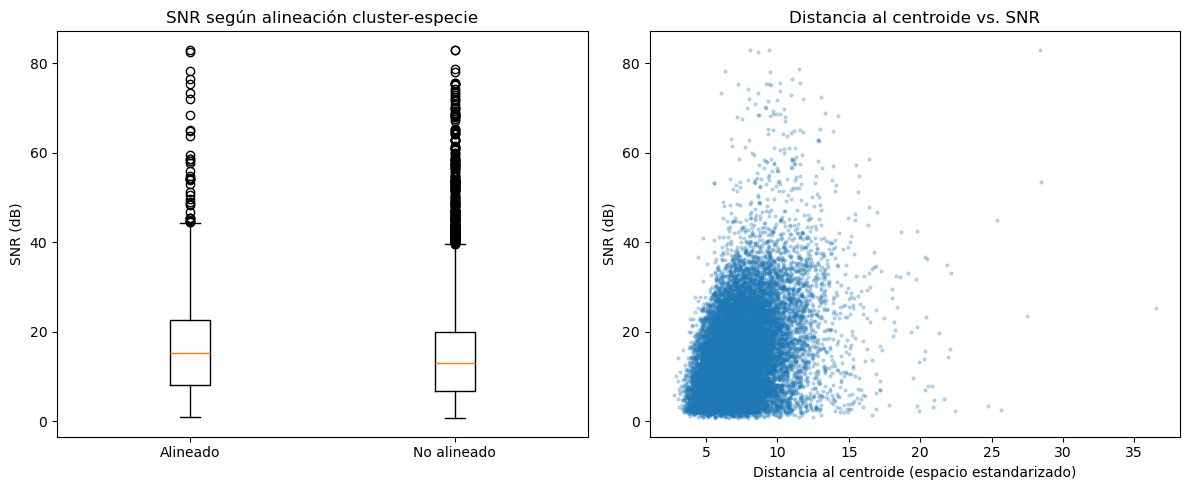

In [7]:
centroids = kmeans.cluster_centers_
dist_to_centroid = np.linalg.norm(X_scaled - centroids[cluster_labels], axis=1)
cluster_majority = pd.Series(y_species).groupby(cluster_labels).agg(lambda labels: labels.value_counts().idxmax())
majority_per_clip = cluster_majority.reindex(cluster_labels).to_numpy()
aligned = majority_per_clip == y_species

snr = df["snr_db"].to_numpy(dtype=np.float64)
inband = df["inband_energy_ratio"].to_numpy(dtype=np.float64)
rho_snr, p_snr = spearmanr(dist_to_centroid, snr)
rho_inband, p_inband = spearmanr(dist_to_centroid, inband)

print(f"Alineados con especie mayoritaria: {aligned.sum():,}/{len(aligned):,} ({aligned.mean():.1%})")
print(f"SNR medio alineados: {snr[aligned].mean():.2f} dB")
print(f"SNR medio no alineados: {snr[~aligned].mean():.2f} dB")
print(f"Spearman(distancia, SNR): rho={rho_snr:.4f}, p={p_snr:.3g}")
print(f"Spearman(distancia, inband_energy_ratio): rho={rho_inband:.4f}, p={p_inband:.3g}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].boxplot([snr[aligned], snr[~aligned]], tick_labels=["Alineado", "No alineado"])
axes[0].set_ylabel("SNR (dB)")
axes[0].set_title("SNR según alineación cluster-especie")
axes[1].scatter(dist_to_centroid, snr, s=4, alpha=0.25)
axes[1].set_xlabel("Distancia al centroide (espacio estandarizado)")
axes[1].set_ylabel("SNR (dB)")
axes[1].set_title("Distancia al centroide vs. SNR")
fig.tight_layout()
display_figure(fig)

## Paso 7 — Guardar asignaciones y métricas

Se guardan las asignaciones por clip y las métricas necesarias para reproducir y comparar esta ejecución.

In [8]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
assignments = df[["clip_id", "recording_id", "primary_label", "author", "partition"]].copy()
assignments["cluster_id"] = cluster_labels
assignments[["pca_1", "pca_2", "pca_3"]] = coords
assignments.to_csv(OUT_DIR / "cluster_assignments.csv", index=False)

metrics = {
    "seed": SEED,
    "n_clusters": N_CLUSTERS,
    "n_clips_used": int(len(df)),
    "feature_columns_used": int(len(feature_columns)),
    "adjusted_rand_index": float(ari),
    "silhouette_score": float(silhouette_full),
    "silhouette_sample_size": int(len(X_scaled)),
    "pca_explained_variance_ratio": [float(value) for value in pca.explained_variance_ratio_],
    "n_clips_aligned_with_cluster_majority_species": int(aligned.sum()),
    "snr_db_mean_aligned": float(snr[aligned].mean()),
    "snr_db_mean_misaligned": float(snr[~aligned].mean()),
    "spearman_dist_vs_snr_db": {"rho": float(rho_snr), "p_value": float(p_snr)},
    "spearman_dist_vs_inband_energy_ratio": {"rho": float(rho_inband), "p_value": float(p_inband)},
    "seed_validation": [
        {key: (int(value) if key == "semilla" else float(value)) for key, value in row.items()}
        for row in seed_results
    ],
    "seed_pairwise_ari": {
        str(seed_a): {str(seed_b): float(seed_comparison.loc[seed_b, seed_a]) for seed_b in SEED_VALIDATION}
        for seed_a in SEED_VALIDATION
    },
}
with (OUT_DIR / "clustering_metrics.json").open("w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=2, ensure_ascii=False)

print(f"Asignaciones guardadas en: {OUT_DIR / 'cluster_assignments.csv'}")
print(f"Métricas guardadas en: {OUT_DIR / 'clustering_metrics.json'}")

Asignaciones guardadas en: /Users/veroserna1/Github repositories/Proyecto 1 MIAA/experiments/results/hito4_5/clustering/cluster_assignments.csv
Métricas guardadas en: /Users/veroserna1/Github repositories/Proyecto 1 MIAA/experiments/results/hito4_5/clustering/clustering_metrics.json


In [9]:
import json
import pandas as pd

# 1. Cargar el archivo JSON generado
json_path = OUT_DIR / "clustering_metrics.json"
with json_path.open("r", encoding="utf-8") as f:
    data = json.load(f)

# 2. Tabla de validación por semilla (seed_validation)
df_seed_val = pd.DataFrame(data["seed_validation"])
print("--- Seed Validation ---")
display(df_seed_val)

# 3. Matriz de comparación entre semillas (seed_pairwise_ari)
df_pairwise_ari = pd.DataFrame(data["seed_pairwise_ari"])
print("\n--- Seed Pairwise ARI ---")
display(df_pairwise_ari)


--- Seed Validation ---


,semilla,ARI_vs_especie,Silhouette_todos_los_clips
0,42,0.032025,0.020624
1,7,0.031230,0.020143
2,21,0.032205,0.017264
3,99,0.030812,0.018649
4,123,0.033457,0.016300



--- Seed Pairwise ARI ---


,42,7,21,99,123
42,1.000000,0.891293,0.634622,0.851024,0.639951
7,0.891293,1.000000,0.595084,0.816523,0.604494
21,0.634622,0.595084,1.000000,0.594967,0.881156
99,0.851024,0.816523,0.594967,1.000000,0.589728
123,0.639951,0.604494,0.881156,0.589728,1.000000


## Gráficas complementarias del reporte

Estas figuras completan las que ya se muestran en los pasos anteriores. La proyección PCA 2D, la proyección PCA 3D y la relación entre distancia al centroide y SNR ya aparecen en el Paso 5 y el Paso 6; aquí se incluyen las otras gráficas del [reporte del Hito 4](../docs/hito4_clustering_report.md).

### Métricas principales: ARI y Silhouette

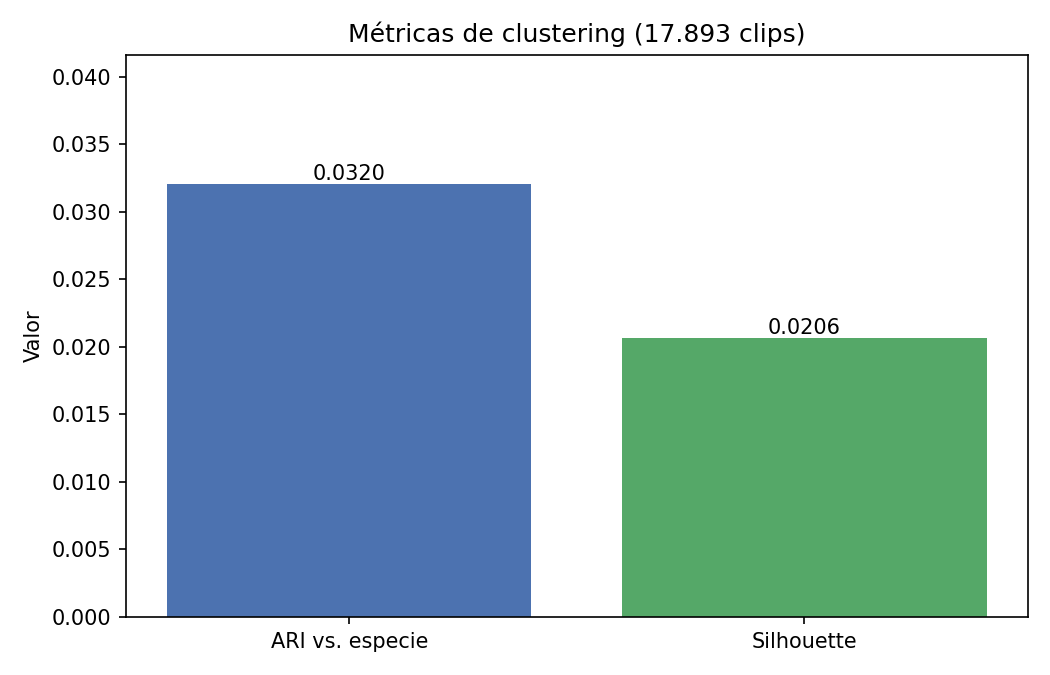

### Alineación entre clusters y especie mayoritaria

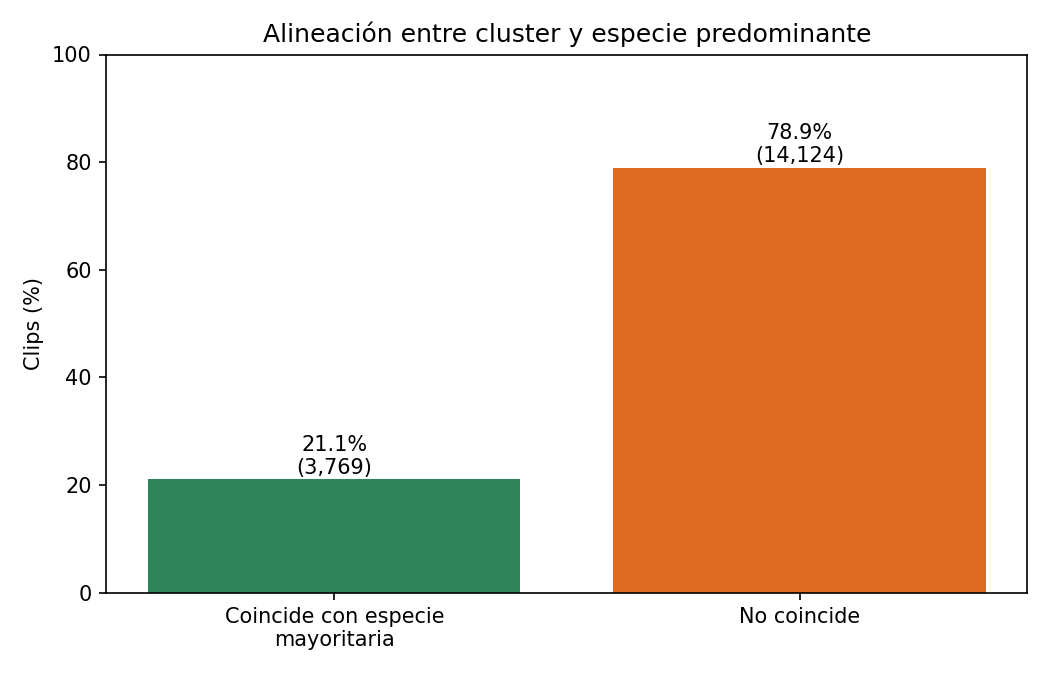

### SNR medio según alineación

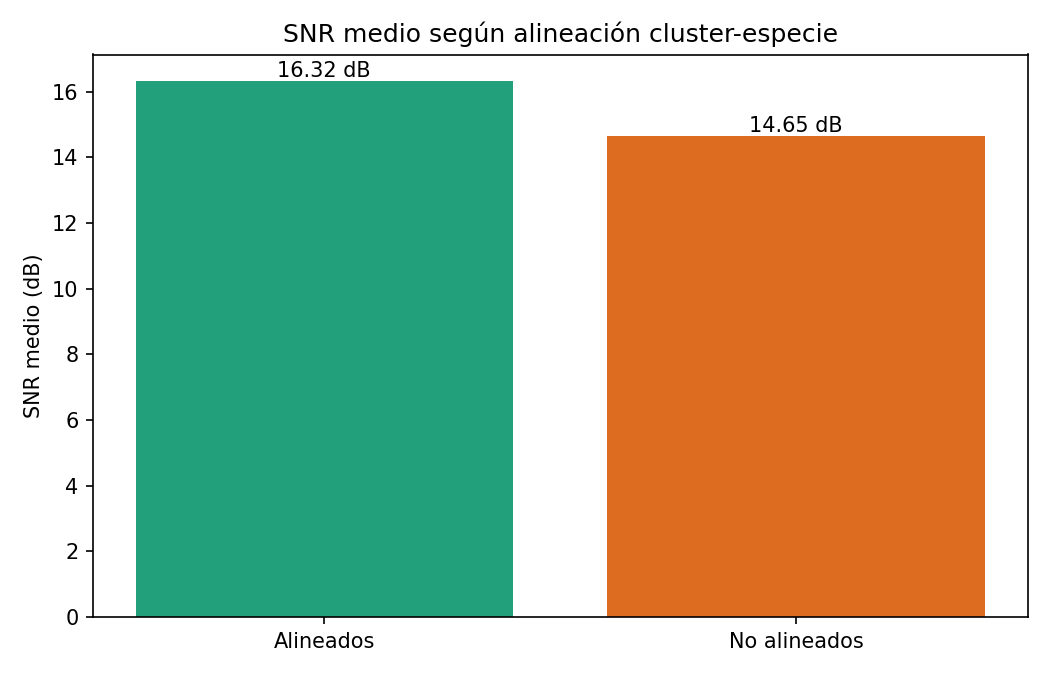

### Estabilidad de K-Means ante la semilla

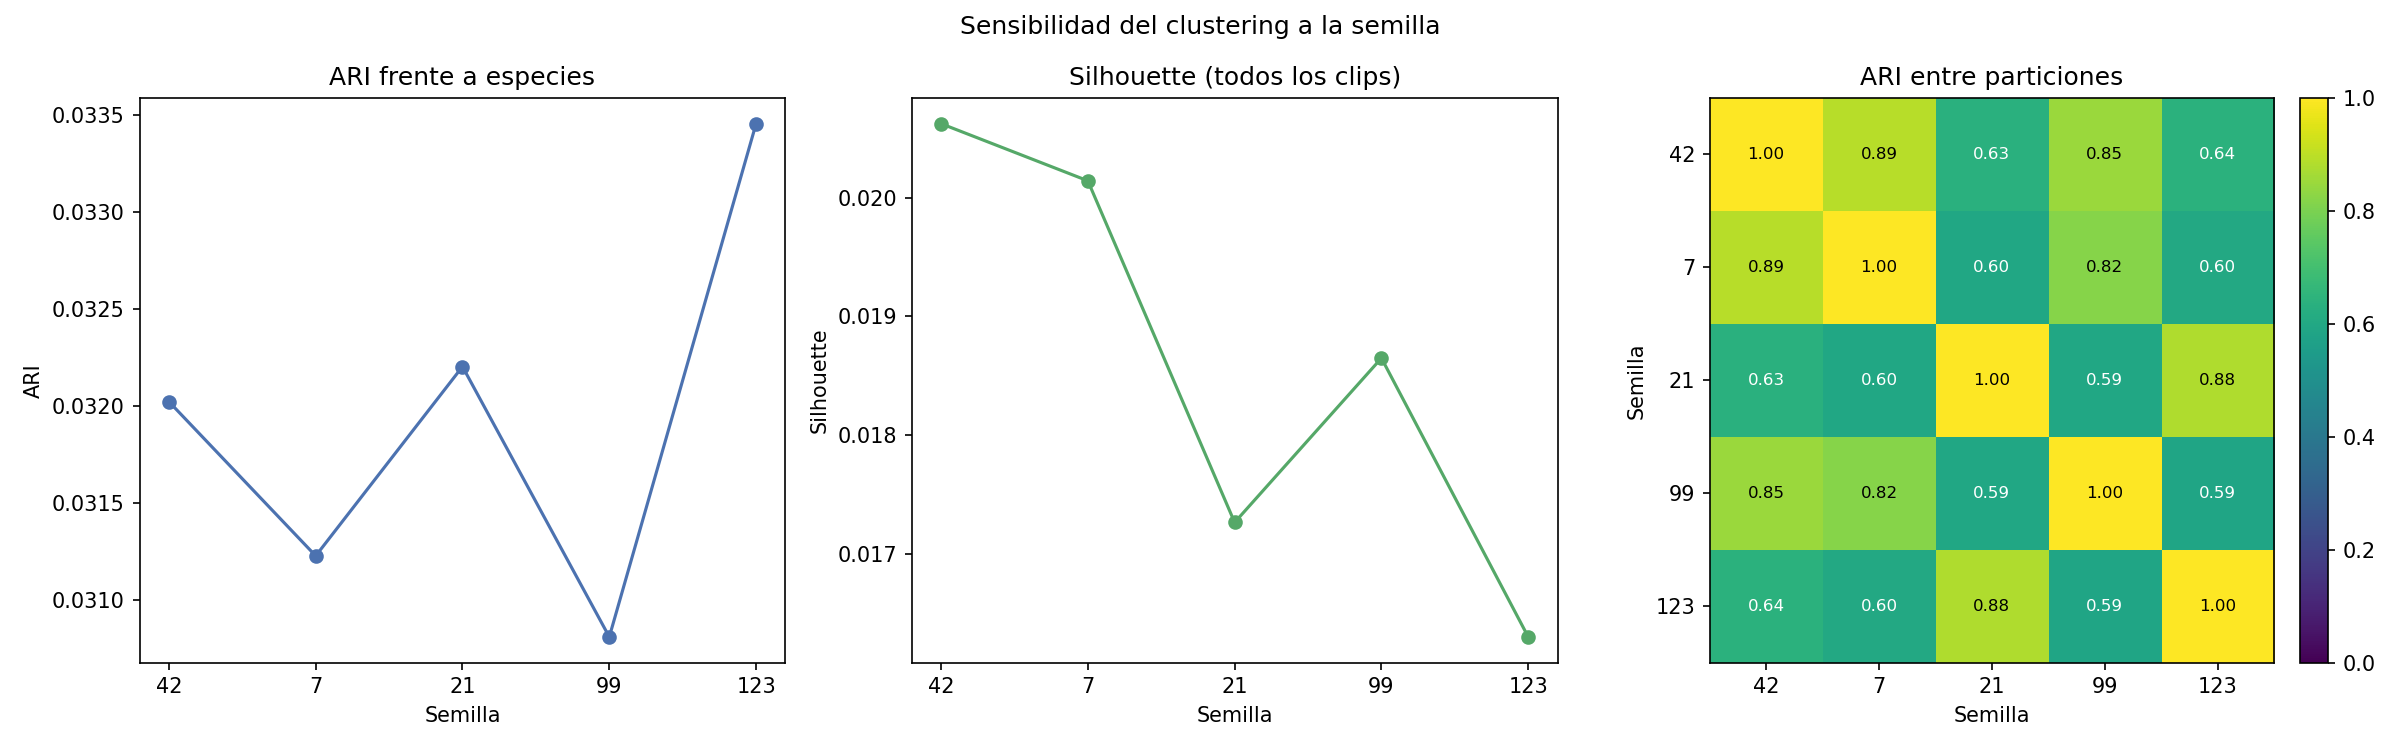

In [10]:
from IPython.display import Image, Markdown, display

report_figures = [
    ("Métricas principales: ARI y Silhouette", "metric_comparison.png"),
    ("Alineación entre clusters y especie mayoritaria", "cluster_alignment.png"),
    ("SNR medio según alineación", "snr_alignment.png"),
    ("Estabilidad de K-Means ante la semilla", "seed_stability.png"),
]
report_figures_dir = PROJECT_ROOT / "docs" / "assets" / "hito4"

for title, filename in report_figures:
    image_path = report_figures_dir / filename
    if not image_path.is_file():
        raise FileNotFoundError(f"No se encontró la figura del reporte: {image_path}")
    display(Markdown(f"### {title}"))
    display(Image(filename=str(image_path)))

## Conclusión

Con **17,893 clips**, 90 características y *k* = 16, K-Means no recupera de manera útil las especies: el **ARI fue 0.0320** (casi cero) y la **Silhouette fue 0.0206** (cercana a cero), lo que indica poca concordancia con las etiquetas reales y escasa separación entre clusters. Solo **3,769 clips (21.1 %)** coincidieron con la especie mayoritaria de su cluster.

La conclusión se mantiene al cambiar la inicialización: en cinco semillas el ARI frente a especies varió de **0.0308 a 0.0335** y la Silhouette de **0.0163 a 0.0206**. Sin embargo, los ARI entre pares de particiones estuvieron entre **0.590 y 0.891**, señal de que algunas asignaciones sí cambian según la semilla.

Como análisis complementario, la distancia al centroide tuvo correlación positiva con SNR (**Spearman ρ = 0.348**) y con `inband_energy_ratio` (**ρ = 0.271, p = 6.24e-298**); esto describe una asociación con la calidad del audio, no causalidad. Las tres componentes PCA explican **36.7 %** de la varianza. En conjunto, la evidencia respalda que K-Means no separa bien las especies en este espacio no supervisado; no implica que las características sean inútiles para clasificación supervisada.